# Progetto 1: Segmentazione Clienti + Churn Prediction (Telco Customer Churn)
**Corso:** Laboratorio di Intelligenza Artificiale — A.A. 2025/2026  
**Autore:** Massimo Mantineo (Matricola: 541924)

## Introduzione e Obiettivi Formativi
Questo notebook implementa la pipeline completa per il dataset **IBM Telco Customer Churn**, articolata in due fasi integrate:
1. **Apprendimento non supervisionato (Clustering K-Means + PCA):** Segmentazione comportamentale dei clienti senza l'uso dell'etichetta `Churn`.
2. **Apprendimento supervisionato (Classificazione Binaria):** Confronto tra una baseline lineare (**Regressione Logistica**), un modello White-Box (**Decision Tree CART**, `max_depth=5`) e una rete neurale (**MLP**, con regolarizzazione L2 ed *early stopping*), valutando l'impatto dell'aggiunta dei cluster e il trade-off Precision/Recall guidato dal costo di acquisizione (CAC).

> **Rigore metodologico (Zero Data Leakage):** lo split stratificato 80/20 viene effettuato *prima* dello scaling, del clustering K-Means e della PCA, che vengono addestrati esclusivamente sul Training Set e poi applicati al Test Set.

## Setup e Configurazione Parametri
Raccogliamo in questa sezione gli import e gli iperparametri globali per garantire la completa riproducibilità degli esperimenti.

In [1]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    confusion_matrix, roc_curve
)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression

# --- Configurazione Globale ---
IMAGES_DIR = "../relazione/images" if os.path.exists("../relazione") else "relazione/images"
RANDOM_STATE = 42
TEST_SIZE = 0.20

# Parametri K-Means (valutazione per K in {2, 3, 4, 5, 6})
K_MIN = 2
K_MAX = 7
SELECTED_K = 3
KMEANS_N_INIT = 10

# Parametri MLP (Lezione 08: regolarizzazione L2 esplicita + early stopping)
MLP_HIDDEN_LAYERS = (64, 32)
MLP_ALPHA = 0.1
MLP_MAX_ITER = 500

os.makedirs(IMAGES_DIR, exist_ok=True)

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
warnings.filterwarnings('ignore')

## 1. Caricamento dei Dati ed Esplorazione Iniziale
Carichiamo il dataset originale `Telco-Customer-Churn.csv` e ne ispezioniamo dimensioni, colonne e tipi di dato.

In [2]:
possible_data_paths = [
    "../data/Telco-Customer-Churn.csv",
    "data/Telco-Customer-Churn.csv",
]
DATA_PATH = next((p for p in possible_data_paths if os.path.exists(p)), possible_data_paths[0])

df = pd.read_csv(DATA_PATH)
print(f"Dimensioni del dataset: {df.shape[0]} righe, {df.shape[1]} colonne\n")
print("Tipi di dato:")
print(df.dtypes)
display(df.head())

Dimensioni del dataset: 7043 righe, 21 colonne

Tipi di dato:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Pulizia dei Dati
Dall'ispezione iniziale emergono tre interventi necessari:
- **`customerID`:** identificativo univoco privo di capacità predittiva, da rimuovere (restano **19 feature** di ingresso e **1 target**).
- **`TotalCharges`:** importato come stringa (`object`/`str`) a causa di **11 righe con spazio bianco `" "`**; tali righe corrispondono esattamente a nuovi clienti con `tenure == 0` che non hanno ancora completato il primo ciclo di fatturazione, per cui vengono imputate a `0.0` e convertite in `float64`.
- **`Churn`:** variabile target binaria convertita da `Yes`/`No` a `1`/`0`.

In [3]:
blank_rows = df[df['TotalCharges'].astype(str).str.strip() == ""]
print(f"Numero di righe con TotalCharges vuoto: {len(blank_rows)}")
print("Valori unici di tenure per queste righe:", blank_rows['tenure'].unique().tolist())

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].astype(str).str.strip().replace("", "0"))
df = df.drop(columns=['customerID'])
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print("\nTipi dopo la pulizia:")
print(df[['TotalCharges', 'Churn']].dtypes)
print(f"Valori nulli totali nel dataset: {df.isnull().sum().sum()}")

Numero di righe con TotalCharges vuoto: 11
Valori unici di tenure per queste righe: [0]

Tipi dopo la pulizia:
TotalCharges    float64
Churn             int64
dtype: object
Valori nulli totali nel dataset: 0


## 3. Analisi Esplorativa dei Dati (EDA)
Verifichiamo la distribuzione della variabile target (`Churn`) e confrontiamo `tenure` e `MonthlyCharges` tra clienti rimasti e clienti in abbandono.

Tasso di churn complessivo nel dataset: 26.54% (1869 / 7043)

Mediane per classe (0 = Rimasti, 1 = Abbandoni):


,tenure,MonthlyCharges
Churn,,
0,38.0,64.43
1,10.0,79.65


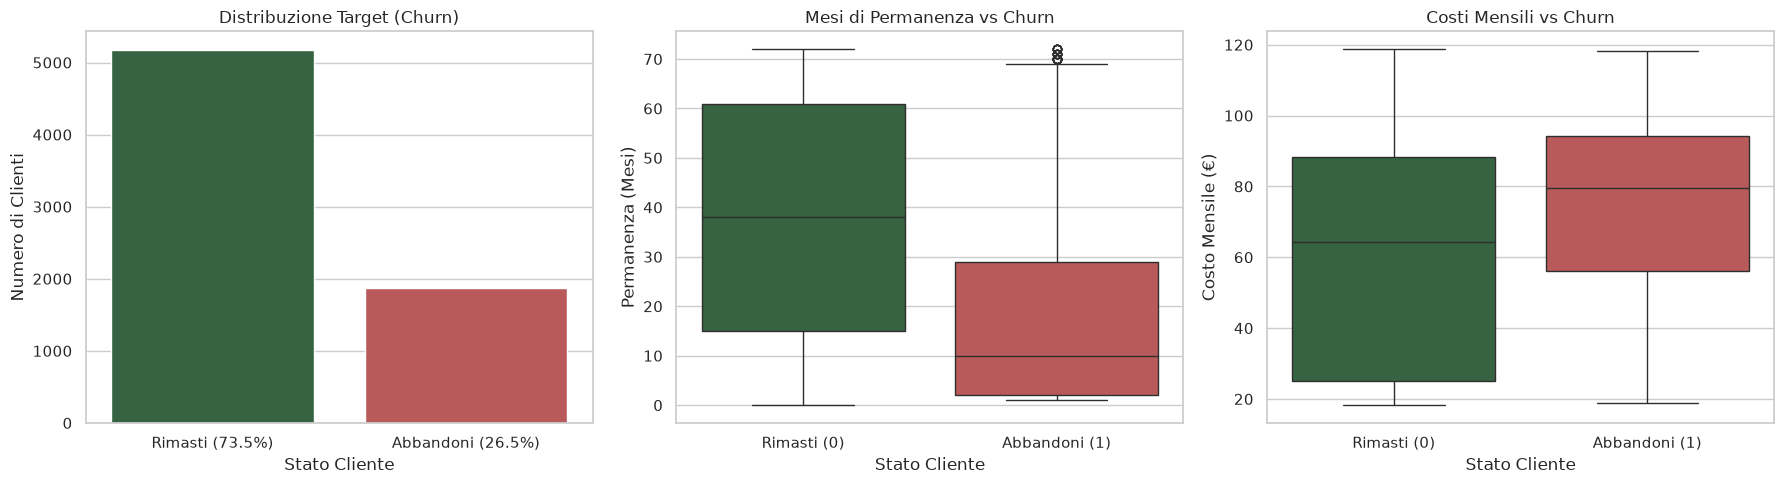

In [4]:
churn_rate = df['Churn'].mean()
med_stats = df.groupby('Churn')[['tenure', 'MonthlyCharges']].median()
print(f"Tasso di churn complessivo nel dataset: {churn_rate:.2%} ({df['Churn'].sum()} / {len(df)})")
print("\nMediane per classe (0 = Rimasti, 1 = Abbandoni):")
display(med_stats.round(2))

palette_churn = ['#2E6B3E', '#C94A4A']

# 1. Grafico a 3 pannelli per la relazione (distribuzione_churn.png)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(x='Churn', data=df, ax=axes[0], palette=palette_churn)
axes[0].set_title('Distribuzione Target (Churn)')
axes[0].set_xlabel('Stato Cliente')
axes[0].set_ylabel('Numero di Clienti')
axes[0].set_xticklabels(['Rimasti (73.5%)', 'Abbandoni (26.5%)'])

sns.boxplot(x='Churn', y='tenure', data=df, ax=axes[1], palette=palette_churn)
axes[1].set_title('Mesi di Permanenza vs Churn')
axes[1].set_xlabel('Stato Cliente')
axes[1].set_ylabel('Permanenza (Mesi)')
axes[1].set_xticklabels(['Rimasti (0)', 'Abbandoni (1)'])

sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=axes[2], palette=palette_churn)
axes[2].set_title('Costi Mensili vs Churn')
axes[2].set_xlabel('Stato Cliente')
axes[2].set_ylabel('Costo Mensile (€)')
axes[2].set_xticklabels(['Rimasti (0)', 'Abbandoni (1)'])

plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/distribuzione_churn.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. Grafico boxplot a 2 pannelli per le slide (boxplot_permanenza_costi.png)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

sns.boxplot(x='Churn', y='tenure', data=df, ax=axes[0], palette=palette_churn, width=0.55)
axes[0].set_title('Permanenza (Mesi)\n[Linea nera = Mediana]', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Mesi di Abbonamento')
axes[0].set_xticklabels(['Rimasti', 'Abbandoni'], fontweight='bold')

sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=axes[1], palette=palette_churn, width=0.55)
axes[1].set_title('Costo Mensile (€)\n[Linea nera = Mediana]', fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Spesa Mensile (€)')
axes[1].set_xticklabels(['Rimasti', 'Abbandoni'], fontweight='bold')

plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/boxplot_permanenza_costi.png', dpi=300, bbox_inches='tight')
plt.close(fig)

## 4. Split Stratificato e Preprocessing (Zero Data Leakage)
Per evitare qualsiasi contaminazione tra Training e Test Set (*Data Leakage*):
1. Effettuiamo subito lo **split stratificato 80/20** (`5.634` istanze di training, `1.409` di test), preservando esattamente il `26.54%` di Churn in entrambi i sottoinsiemi.
2. Costruiamo `preprocessor_scaled` (`StandardScaler` sulle 3 variabili numeriche + `OneHotEncoder(drop='first')` sulle 16 categoriali $\rightarrow$ **30 feature**), addestrato **solo** sul Training Set (`fit_transform`) e poi applicato al Test Set (`transform`). Questa rappresentazione alimenta **K-Means**, **PCA**, **Regressione Logistica** e **MLP**.
3. Costruiamo `preprocessor_tree` (`passthrough` sulle variabili numeriche + `OneHotEncoder(drop='first')`) per il **Decision Tree CART**: come visto a lezione, gli alberi decisionali sono invarianti alle trasformazioni monotone delle singole feature e in questo modo producono regole direttamente leggibili in **mesi** ed **Euro (€)**.

In [5]:
X_raw = df.drop(columns=['Churn'])
y = df['Churn']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [col for col in X_raw.columns if col not in num_cols]

# Pipeline con Standardizzazione (per K-Means, PCA, LogReg, MLP)
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)
X_train_scaled = preprocessor_scaled.fit_transform(X_train_raw)
X_test_scaled = preprocessor_scaled.transform(X_test_raw)

cat_names = list(preprocessor_scaled.named_transformers_['cat'].get_feature_names_out(cat_cols))
feature_names = num_cols + cat_names

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=feature_names, index=X_train_raw.index)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=feature_names, index=X_test_raw.index)

# Pipeline senza scaling (per Decision Tree CART interpretabile in unità originali)
preprocessor_tree = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)
X_train_tree = preprocessor_tree.fit_transform(X_train_raw)
X_test_tree = preprocessor_tree.transform(X_test_raw)

X_train_tree_df = pd.DataFrame(X_train_tree, columns=feature_names, index=X_train_raw.index)
X_test_tree_df = pd.DataFrame(X_test_tree, columns=feature_names, index=X_test_raw.index)

print(f"Train Set: {X_train_scaled_df.shape} (Churn={y_train.mean():.2%})")
print(f"Test Set : {X_test_scaled_df.shape} (Churn={y_test.mean():.2%})")
display(X_train_scaled_df.head())

Train Set: (5634, 30) (Churn=26.54%)
Test Set : (1409, 30) (Churn=26.54%)


,tenure,MonthlyCharges,TotalCharges,gender_Male,SeniorCitizen_1,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0.102371,-0.521976,-0.262257,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3151,-0.711743,0.337478,-0.503635,1.0,0.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4860,-0.793155,-0.809013,-0.749883,1.0,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3867,-0.263980,0.284384,-0.172722,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0
3810,-1.281624,-0.676279,-0.989374,1.0,0.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


## 5. Apprendimento Non Supervisionato: Clustering K-Means
Addestriamo K-Means **esclusivamente sul Training Set standardizzato (`X_train_scaled`)** senza utilizzare l'etichetta `Churn`.
Valutiamo $K \in \{2, 3, 4, 5, 6\}$ combinando:
- **Inerzia (WCSS):** somma delle distanze quadratiche intra-cluster (Metodo del Gomito).
- **Silhouette Score:** misura combinata di coesione interna e separazione tra cluster ($s \in [-1, +1]$), stimata su un campione casuale riproducibile di 2.000 istanze di training (`random_state=42`).

Tabella Valutazione Clustering (Training Set, 30 feature):


,K,Inerzia,Silhouette
0,2,33485.3863,0.2930
1,3,24642.3214,0.2817
2,4,22599.7888,0.2304
3,5,21178.5254,0.2093
4,6,19983.5212,0.1848


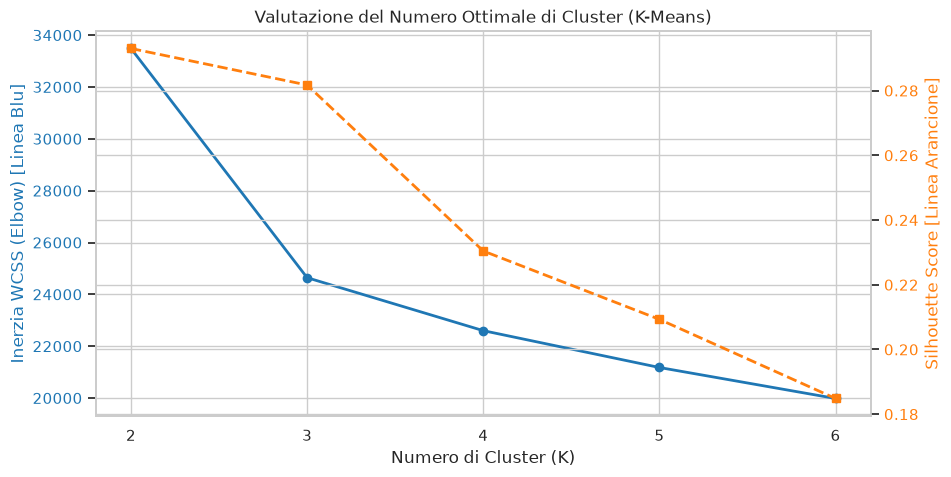

In [6]:
inertias = []
silhouettes = []
k_range = list(range(K_MIN, K_MAX))
cluster_results = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=KMEANS_N_INIT)
    labels_k = km.fit_predict(X_train_scaled)
    sil = silhouette_score(X_train_scaled, labels_k, sample_size=2000, random_state=RANDOM_STATE)
    inertias.append(km.inertia_)
    silhouettes.append(sil)
    cluster_results.append({"K": k, "Inerzia": km.inertia_, "Silhouette": sil})

cluster_results_df = pd.DataFrame(cluster_results)
print("Tabella Valutazione Clustering (Training Set, 30 feature):")
display(cluster_results_df.round(4))

fig, ax1 = plt.subplots(figsize=(10, 5))
color_in = 'tab:blue'
ax1.set_xlabel('Numero di Cluster (K)')
ax1.set_ylabel('Inerzia WCSS (Elbow) [Linea Blu]', color=color_in)
ax1.plot(k_range, inertias, marker='o', color=color_in, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color_in)
ax1.set_xticks(k_range)

ax2 = ax1.twinx()
color_sil = 'tab:orange'
ax2.set_ylabel('Silhouette Score [Linea Arancione]', color=color_sil)
ax2.plot(k_range, silhouettes, marker='s', color=color_sil, linewidth=2, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color_sil)

plt.title('Valutazione del Numero Ottimale di Cluster (K-Means)')
plt.savefig(f'{IMAGES_DIR}/clustering_scelta_k.png', dpi=300, bbox_inches='tight')
plt.show()

### 5.1 Scelta di $K=3$, Profilazione dei Segmenti e Predizione sul Test Set
Dall'analisi combinata di Inerzia e Silhouette sul Training Set:
- **$K=2$** ottiene la Silhouette più alta (`0.2930`), ma produce una dicotomia elementare tra clienti con e senza servizio internet, senza isolare la dinamica di permanenza (`tenure`).
- **$K=3$** si colloca esattamente sul punto di gomito dell'Inerzia (`33.485 -> 24.642`, con riduzione marginale da `K=4` in poi) mantenendo un Silhouette Score pressoché invariato (`0.2817`), valore coerente con uno spazio 30-dimensionale misto ricco di variabili binarie one-hot.
- **$K \ge 4$** determina un netto calo della Silhouette (`0.2304 -> 0.1848`), segnale di frammentazione artificiale (*over-clustering*).

Riordiniamo deterministicamente gli ID dei cluster per tasso di churn decrescente (`0: Volatili`, `1: Fedeli High-Value`, `2: Low-Cost`) e applichiamo `.predict()` sul Test Set senza data leakage.

Profilo Medio dei 3 Cluster (Training Set):


,Tenure Media,Costo Mensile (€),Costo Totale (€),Tasso Churn,Clienti
Cluster,,,,,
0,15.169,67.873,1005.532,0.434,2557
1,57.728,89.442,5145.229,0.159,1863
2,30.220,21.115,657.121,0.072,1214



Verifica Tasso di Churn per Cluster sul Test Set:


,mean,count
Cluster,,
0,0.433,677
1,0.133,420
2,0.080,312


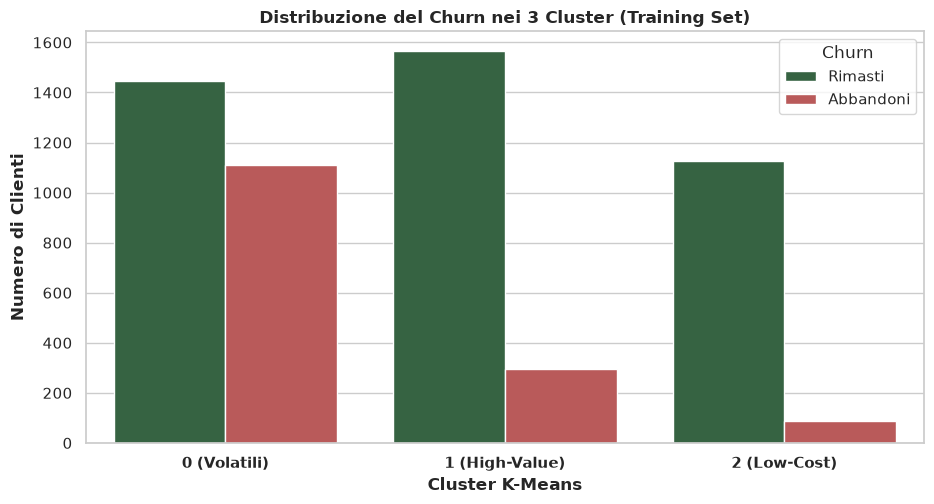

In [7]:
kmeans_chosen = KMeans(n_clusters=SELECTED_K, random_state=RANDOM_STATE, n_init=KMEANS_N_INIT)
raw_train_clusters = kmeans_chosen.fit_predict(X_train_scaled)
raw_test_clusters = kmeans_chosen.predict(X_test_scaled)

# Riordino deterministico degli ID per tasso di churn decrescente sul Training Set:
# Cluster 0 = Volatili (churn massimo), Cluster 1 = Fedeli High-Value, Cluster 2 = Low-Cost (churn minimo)
cluster_order = (
    pd.Series(y_train.values)
    .groupby(raw_train_clusters)
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)
cluster_remap = {old_id: new_id for new_id, old_id in enumerate(cluster_order)}
train_clusters = np.array([cluster_remap[c] for c in raw_train_clusters])
test_clusters = np.array([cluster_remap[c] for c in raw_test_clusters])

df_train_clustered = X_train_raw.copy()
df_train_clustered['Churn'] = y_train
df_train_clustered['Cluster'] = train_clusters

cluster_profile = df_train_clustered.groupby('Cluster').agg({
    'tenure': 'mean',
    'MonthlyCharges': 'mean',
    'TotalCharges': 'mean',
    'Churn': ['mean', 'count']
})
cluster_profile.columns = ['Tenure Media', 'Costo Mensile (€)', 'Costo Totale (€)', 'Tasso Churn', 'Clienti']
print("Profilo Medio dei 3 Cluster (Training Set):")
display(cluster_profile.round(3))

# Verifica coerenza sul Test Set (solo diagnostica)
df_test_clustered = X_test_raw.copy()
df_test_clustered['Churn'] = y_test
df_test_clustered['Cluster'] = test_clusters
print("\nVerifica Tasso di Churn per Cluster sul Test Set:")
display(df_test_clustered.groupby('Cluster')['Churn'].agg(['mean', 'count']).round(3))

# Grafico distribuzione Churn per Cluster
plt.figure(figsize=(9.5, 5.2))
ax = sns.countplot(x='Cluster', hue='Churn', data=df_train_clustered, palette=['#2E6B3E', '#C94A4A'])
plt.title('Distribuzione del Churn nei 3 Cluster (Training Set)', fontweight='bold')
plt.xlabel('Cluster K-Means', fontweight='bold')
plt.ylabel('Numero di Clienti', fontweight='bold')
ax.set_xticklabels(['0 (Volatili)', '1 (High-Value)', '2 (Low-Cost)'], fontweight='bold')
plt.legend(title='Churn', labels=['Rimasti', 'Abbandoni'], frameon=True)
plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/distribuzione_churn_cluster.png', dpi=300, bbox_inches='tight')
plt.show()

### 5.2 Visualizzazione 2D dei Cluster tramite PCA
Applichiamo la **Principal Component Analysis (PCA)** su `X_train_scaled` per proiettare lo spazio 30-dimensionale su due assi ortogonali (`PC1`, `PC2`), verificando sia la varianza spiegata sia i pesi (*loadings*) delle feature principali.

Varianza spiegata: PC1 = 39.37%, PC2 = 18.50%, Totale = 57.87%

PC1 - Top pesi negativi: {'InternetService_No': -0.166, 'OnlineSecurity_No internet service': -0.166, 'OnlineBackup_No internet service': -0.166, 'DeviceProtection_No internet service': -0.166}
PC1 - Top pesi positivi: {'StreamingMovies_Yes': 0.173, 'tenure': 0.338, 'TotalCharges': 0.491, 'MonthlyCharges': 0.501}
PC2 - Top pesi negativi: {'MonthlyCharges': -0.277, 'PaymentMethod_Electronic check': -0.18, 'InternetService_Fiber optic': -0.163, 'PaperlessBilling_Yes': -0.11}
PC2 - Top pesi positivi: {'OnlineBackup_No internet service': 0.192, 'Contract_Two year': 0.221, 'TotalCharges': 0.338, 'tenure': 0.612}


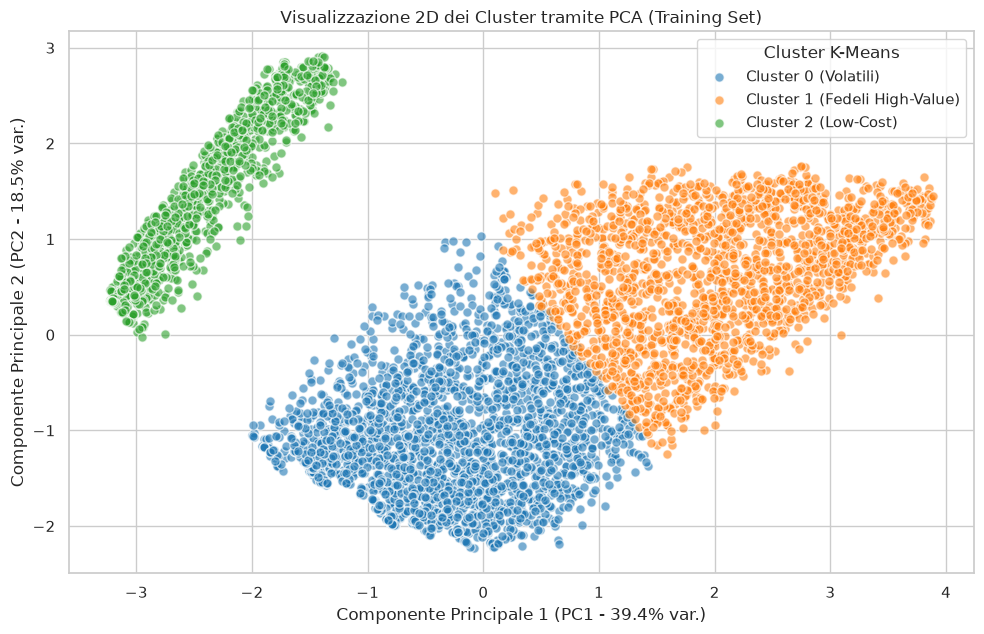

In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)

var_ratio = pca.explained_variance_ratio_
print(f"Varianza spiegata: PC1 = {var_ratio[0]:.2%}, PC2 = {var_ratio[1]:.2%}, Totale = {var_ratio.sum():.2%}\n")

for i in range(2):
    loadings = pd.Series(pca.components_[i], index=feature_names).sort_values()
    print(f"PC{i+1} - Top pesi negativi:", loadings.head(4).round(3).to_dict())
    print(f"PC{i+1} - Top pesi positivi:", loadings.tail(4).round(3).to_dict())

plt.figure(figsize=(10, 6.5))
cluster_names = {
    0: 'Cluster 0 (Volatili)',
    1: 'Cluster 1 (Fedeli High-Value)',
    2: 'Cluster 2 (Low-Cost)'
}
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
for c in range(SELECTED_K):
    mask = train_clusters == c
    plt.scatter(
        X_train_pca[mask, 0], X_train_pca[mask, 1],
        label=cluster_names[c],
        color=colors[c],
        alpha=0.6,
        edgecolors='w',
        s=45
    )

plt.title('Visualizzazione 2D dei Cluster tramite PCA (Training Set)')
plt.xlabel(f'Componente Principale 1 (PC1 - {var_ratio[0]:.1%} var.)')
plt.ylabel(f'Componente Principale 2 (PC2 - {var_ratio[1]:.1%} var.)')
plt.legend(title="Cluster K-Means", frameon=True)
plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/clustering_visualizzazione_pca.png', dpi=300, bbox_inches='tight')
plt.show()

### Analisi Qualitativa dei Segmenti
- **Cluster 0 (Clienti Volatili):** Permanenza breve (~15 mesi), spesa mensile medio-alta (~68 €) e **tasso di Churn critico (~43.4%)**. Costituisce il segmento prioritario su cui concentrare le azioni di retention dell'agente CRM.
- **Cluster 1 (Clienti Fedeli High-Value):** Permanenza lunga (~58 mesi), spesa mensile elevata (~89 €) e **Churn contenuto (~15.9%)**. Rappresenta la base più redditizia e consolidata.
- **Cluster 2 (Clienti Low-Cost):** Permanenza intermedia (~30 mesi), spesa molto bassa (~21 €), servizi telefonici base senza banda larga e **Churn minimo (~7.2%)**.

## 6. Apprendimento Supervisionato: Churn Prediction
Confrontiamo tre famiglie di modelli su due configurazioni prive di leakage:
- **Dataset Base (`Orig`):** 30 feature preprocessate.
- **Dataset Arricchito (`+Clust`):** 30 feature + codifica One-Hot (`drop='first'`) del cluster K-Means assegnato (`Cluster_1`, `Cluster_2`, usando il Cluster 0 come riferimento).

I modelli valutati sono:
1. **Regressione Logistica (Baseline Lineare)**
2. **Decision Tree CART (`max_depth=5`, su feature numeriche non scalate)**
3. **Multi-Layer Perceptron (`hidden_layer_sizes=(64, 32)`, regolarizzazione L2 `alpha=0.1`, `early_stopping=True`)**

In [9]:
ohe_cluster = OneHotEncoder(drop='first', sparse_output=False)
cl_train_dummies = pd.DataFrame(
    ohe_cluster.fit_transform(train_clusters.reshape(-1, 1)),
    columns=['Cluster_1', 'Cluster_2'],
    index=X_train_raw.index
)
cl_test_dummies = pd.DataFrame(
    ohe_cluster.transform(test_clusters.reshape(-1, 1)),
    columns=['Cluster_1', 'Cluster_2'],
    index=X_test_raw.index
)

X_train_scaled_clust = pd.concat([X_train_scaled_df, cl_train_dummies], axis=1)
X_test_scaled_clust = pd.concat([X_test_scaled_df, cl_test_dummies], axis=1)

X_train_tree_clust = pd.concat([X_train_tree_df, cl_train_dummies], axis=1)
X_test_tree_clust = pd.concat([X_test_tree_df, cl_test_dummies], axis=1)

model_specs = [
    (
        'Regressione Logistica (Baseline)',
        LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
        X_train_scaled_df, X_test_scaled_df,
        X_train_scaled_clust, X_test_scaled_clust
    ),
    (
        'Decision Tree (CART)',
        DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=5),
        X_train_tree_df, X_test_tree_df,
        X_train_tree_clust, X_test_tree_clust
    ),
    (
        'MLP (Rete Neurale)',
        MLPClassifier(
            random_state=RANDOM_STATE,
            hidden_layer_sizes=MLP_HIDDEN_LAYERS,
            alpha=MLP_ALPHA,
            early_stopping=True,
            max_iter=MLP_MAX_ITER
        ),
        X_train_scaled_df, X_test_scaled_df,
        X_train_scaled_clust, X_test_scaled_clust
    ),
]

results = []
roc_data = {}
fitted_models = {}

for name, base_model, X_tr_o, X_te_o, X_tr_c, X_te_c in model_specs:
    m_orig = clone(base_model).fit(X_tr_o, y_train)
    y_pred_o = m_orig.predict(X_te_o)
    y_prob_o = m_orig.predict_proba(X_te_o)[:, 1]

    m_clust = clone(base_model).fit(X_tr_c, y_train)
    y_pred_c = m_clust.predict(X_te_c)
    y_prob_c = m_clust.predict_proba(X_te_c)[:, 1]

    fitted_models[name] = {
        'orig': m_orig, 'clust': m_clust,
        'y_pred_o': y_pred_o, 'y_pred_c': y_pred_c,
        'y_prob_o': y_prob_o, 'y_prob_c': y_prob_c,
    }

    results.append({
        'Modello': name,
        'Acc (Orig)': accuracy_score(y_test, y_pred_o),
        'Acc (Clust)': accuracy_score(y_test, y_pred_c),
        'Prec (Orig)': precision_score(y_test, y_pred_o),
        'Prec (Clust)': precision_score(y_test, y_pred_c),
        'Recall (Orig)': recall_score(y_test, y_pred_o),
        'Recall (Clust)': recall_score(y_test, y_pred_c),
        'F1 (Orig)': f1_score(y_test, y_pred_o),
        'F1 (Clust)': f1_score(y_test, y_pred_c),
        'AUC (Orig)': roc_auc_score(y_test, y_prob_o),
        'AUC (Clust)': roc_auc_score(y_test, y_prob_c),
    })

    fpr_o, tpr_o, _ = roc_curve(y_test, y_prob_o)
    fpr_c, tpr_c, _ = roc_curve(y_test, y_prob_c)
    roc_data[name] = {
        'fpr_o': fpr_o, 'tpr_o': tpr_o, 'auc_o': roc_auc_score(y_test, y_prob_o),
        'fpr_c': fpr_c, 'tpr_c': tpr_c, 'auc_c': roc_auc_score(y_test, y_prob_c),
    }

results_df = pd.DataFrame(results)

## 7. Confronto delle Prestazioni e Trade-off Precision/Recall
Visualizziamo tutte le metriche principali (Accuracy, Precision, Recall, F1-Score, AUC-ROC) e la matrice di confusione sul Test Set (`1.409` clienti, di cui `374` in abbandono).

In [10]:
pd.options.display.float_format = '{:,.4f}'.format
print("Tabella Comparativa delle Performance sul Test Set:")
display(results_df)

print("\nMatrici di Confusione sul Test Set (Configurazione Base):")
for name in ['Regressione Logistica (Baseline)', 'Decision Tree (CART)', 'MLP (Rete Neurale)']:
    cm = confusion_matrix(y_test, fitted_models[name]['y_pred_o'])
    tn, fp, fn, tp = cm.ravel()
    print(f"- {name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Tabella Comparativa delle Performance sul Test Set:


,Modello,Acc (Orig),Acc (Clust),Prec (Orig),Prec (Clust),Recall (Orig),Recall (Clust),F1 (Orig),F1 (Clust),AUC (Orig),AUC (Clust)
0,Regressione Logistica (Baseline),0.8062,0.8034,0.6593,0.6540,0.5588,0.5508,0.6049,0.5980,0.8422,0.8420
1,Decision Tree (CART),0.7942,0.7942,0.6312,0.6312,0.5401,0.5401,0.5821,0.5821,0.8267,0.8267
2,MLP (Rete Neurale),0.7999,0.8034,0.6554,0.6655,0.5187,0.5214,0.5791,0.5847,0.8424,0.8429



Matrici di Confusione sul Test Set (Configurazione Base):
- Regressione Logistica (Baseline): TN=927, FP=108, FN=165, TP=209
- Decision Tree (CART): TN=917, FP=118, FN=172, TP=202
- MLP (Rete Neurale): TN=933, FP=102, FN=180, TP=194


### 7.1 Calibrazione della Soglia Decisionale e Costo CAC (Lezione 04)
Con la soglia standard $\tau = 0.50$, i classificatori su classi sbilanciate (`26.54%` positivi) privilegiano l'Accuracy complessiva e lasciano sfuggire circa il 44% dei clienti a rischio (`FN`). Mostriamo come, in accordo con la Lezione 04, la regolazione della soglia su cross-validation (`X_train`) o l'uso di `class_weight='balanced'` permetta all'agente razionale di aumentare fortemente la Recall (minimizzando i Falsi Negativi legati al costo CAC) a fronte di una riduzione controllata della Precision.

In [11]:
# Calibrazione senza data leakage tramite out-of-fold probabilities sul Training Set
oof_probs = cross_val_predict(
    LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
    X_train_scaled_df, y_train, cv=5, method='predict_proba'
)[:, 1]
print(f"CV (5-fold su Training Set) con τ = 0.35 -> Recall: {recall_score(y_train, oof_probs >= 0.35):.4f}, Precision: {precision_score(y_train, oof_probs >= 0.35):.4f}, F1: {f1_score(y_train, oof_probs >= 0.35):.4f}\n")

# Valutazione sul Test Set delle configurazioni selezionate
test_probs_lr = fitted_models['Regressione Logistica (Baseline)']['y_prob_o']
lr_balanced = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight='balanced').fit(
    X_train_scaled_df, y_train
)

threshold_rows = []
for label, y_pred_eval in [
    ("LogReg (soglia standard τ = 0.50)", (test_probs_lr >= 0.50).astype(int)),
    ("LogReg (soglia calibrata τ = 0.35)", (test_probs_lr >= 0.35).astype(int)),
    ("LogReg (class_weight = 'balanced')", lr_balanced.predict(X_test_scaled_df)),
]:
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_eval).ravel()
    threshold_rows.append({
        "Configurazione": label,
        "Accuracy": accuracy_score(y_test, y_pred_eval),
        "Precision": precision_score(y_test, y_pred_eval),
        "Recall": recall_score(y_test, y_pred_eval),
        "F1-Score": f1_score(y_test, y_pred_eval),
        "TP (Intercettati)": tp,
        "FN (Persi)": fn,
        "FP (Falsi Allarmi)": fp,
    })

display(pd.DataFrame(threshold_rows))

CV (5-fold su Training Set) con τ = 0.35 -> Recall: 0.7043, Precision: 0.5649, F1: 0.6270



,Configurazione,Accuracy,Precision,Recall,F1-Score,TP (Intercettati),FN (Persi),FP (Falsi Allarmi)
0,LogReg (soglia standard τ = 0.50),0.8062,0.6593,0.5588,0.6049,209,165,108
1,LogReg (soglia calibrata τ = 0.35),0.7651,0.5445,0.7032,0.6138,263,111,220
2,LogReg (class_weight = 'balanced'),0.7381,0.5043,0.7834,0.6136,293,81,288


### 7.2 Curve ROC (Receiver Operating Characteristic)
Confrontiamo la capacità discriminativa globale al variare della soglia decisionale sui due dataset.

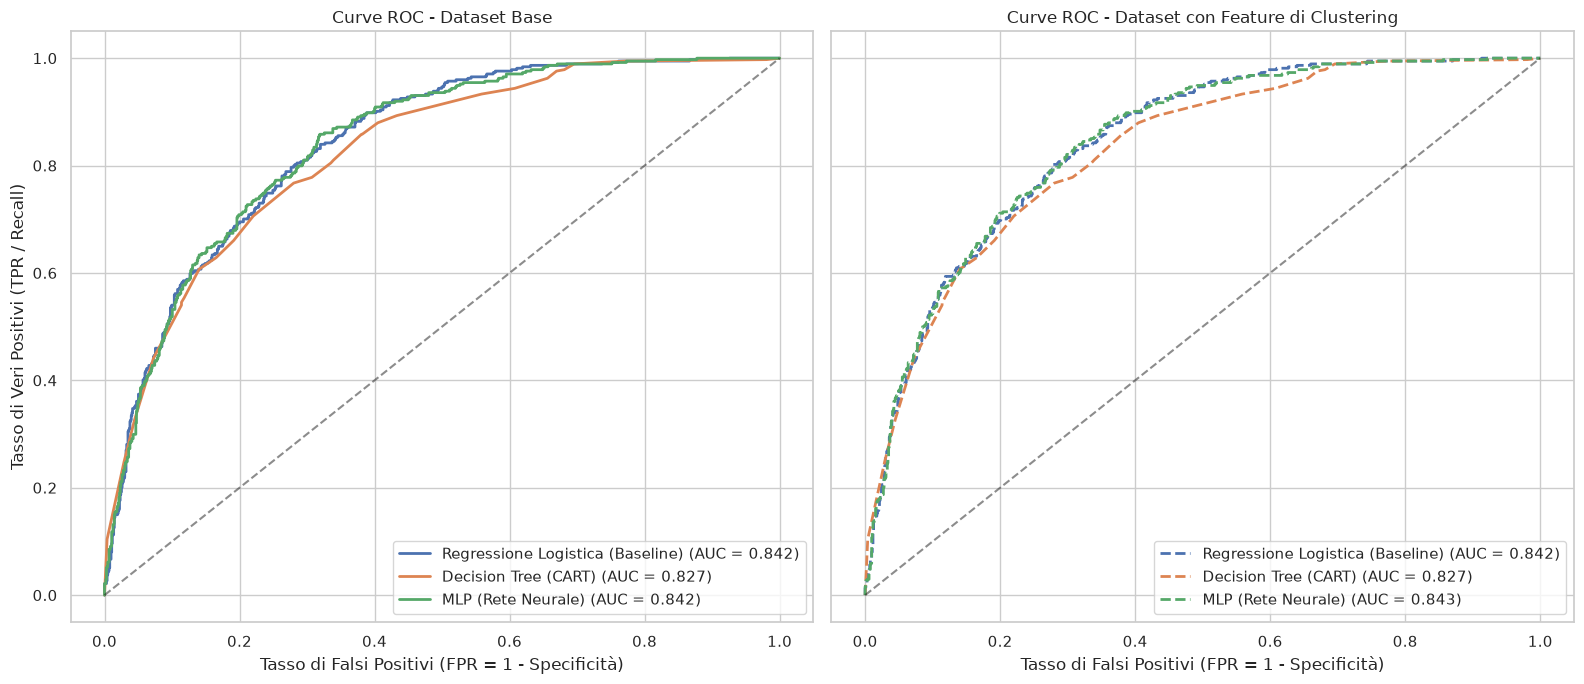

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

for name, data in roc_data.items():
    axes[0].plot(data['fpr_o'], data['tpr_o'], label=f"{name} (AUC = {data['auc_o']:.3f})", linewidth=2)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_xlabel('Tasso di Falsi Positivi (FPR = 1 - Specificità)')
axes[0].set_ylabel('Tasso di Veri Positivi (TPR / Recall)')
axes[0].set_title('Curve ROC - Dataset Base')
axes[0].legend(loc='lower right')

for name, data in roc_data.items():
    axes[1].plot(data['fpr_c'], data['tpr_c'], label=f"{name} (AUC = {data['auc_c']:.3f})", linestyle='--', linewidth=2)
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_xlabel('Tasso di Falsi Positivi (FPR = 1 - Specificità)')
axes[1].set_title('Curve ROC - Dataset con Feature di Clustering')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/curve_roc.png', dpi=300, bbox_inches='tight')
plt.show()

### 7.3 Confronto Visivo delle Prestazioni (Grafico a Barre)
Il grafico sottostante legge **direttamente i valori calcolati in `results_df`** (nessun dato statico/hardcoded), assicurando la piena corrispondenza tra tabella numerica e visualizzazione.

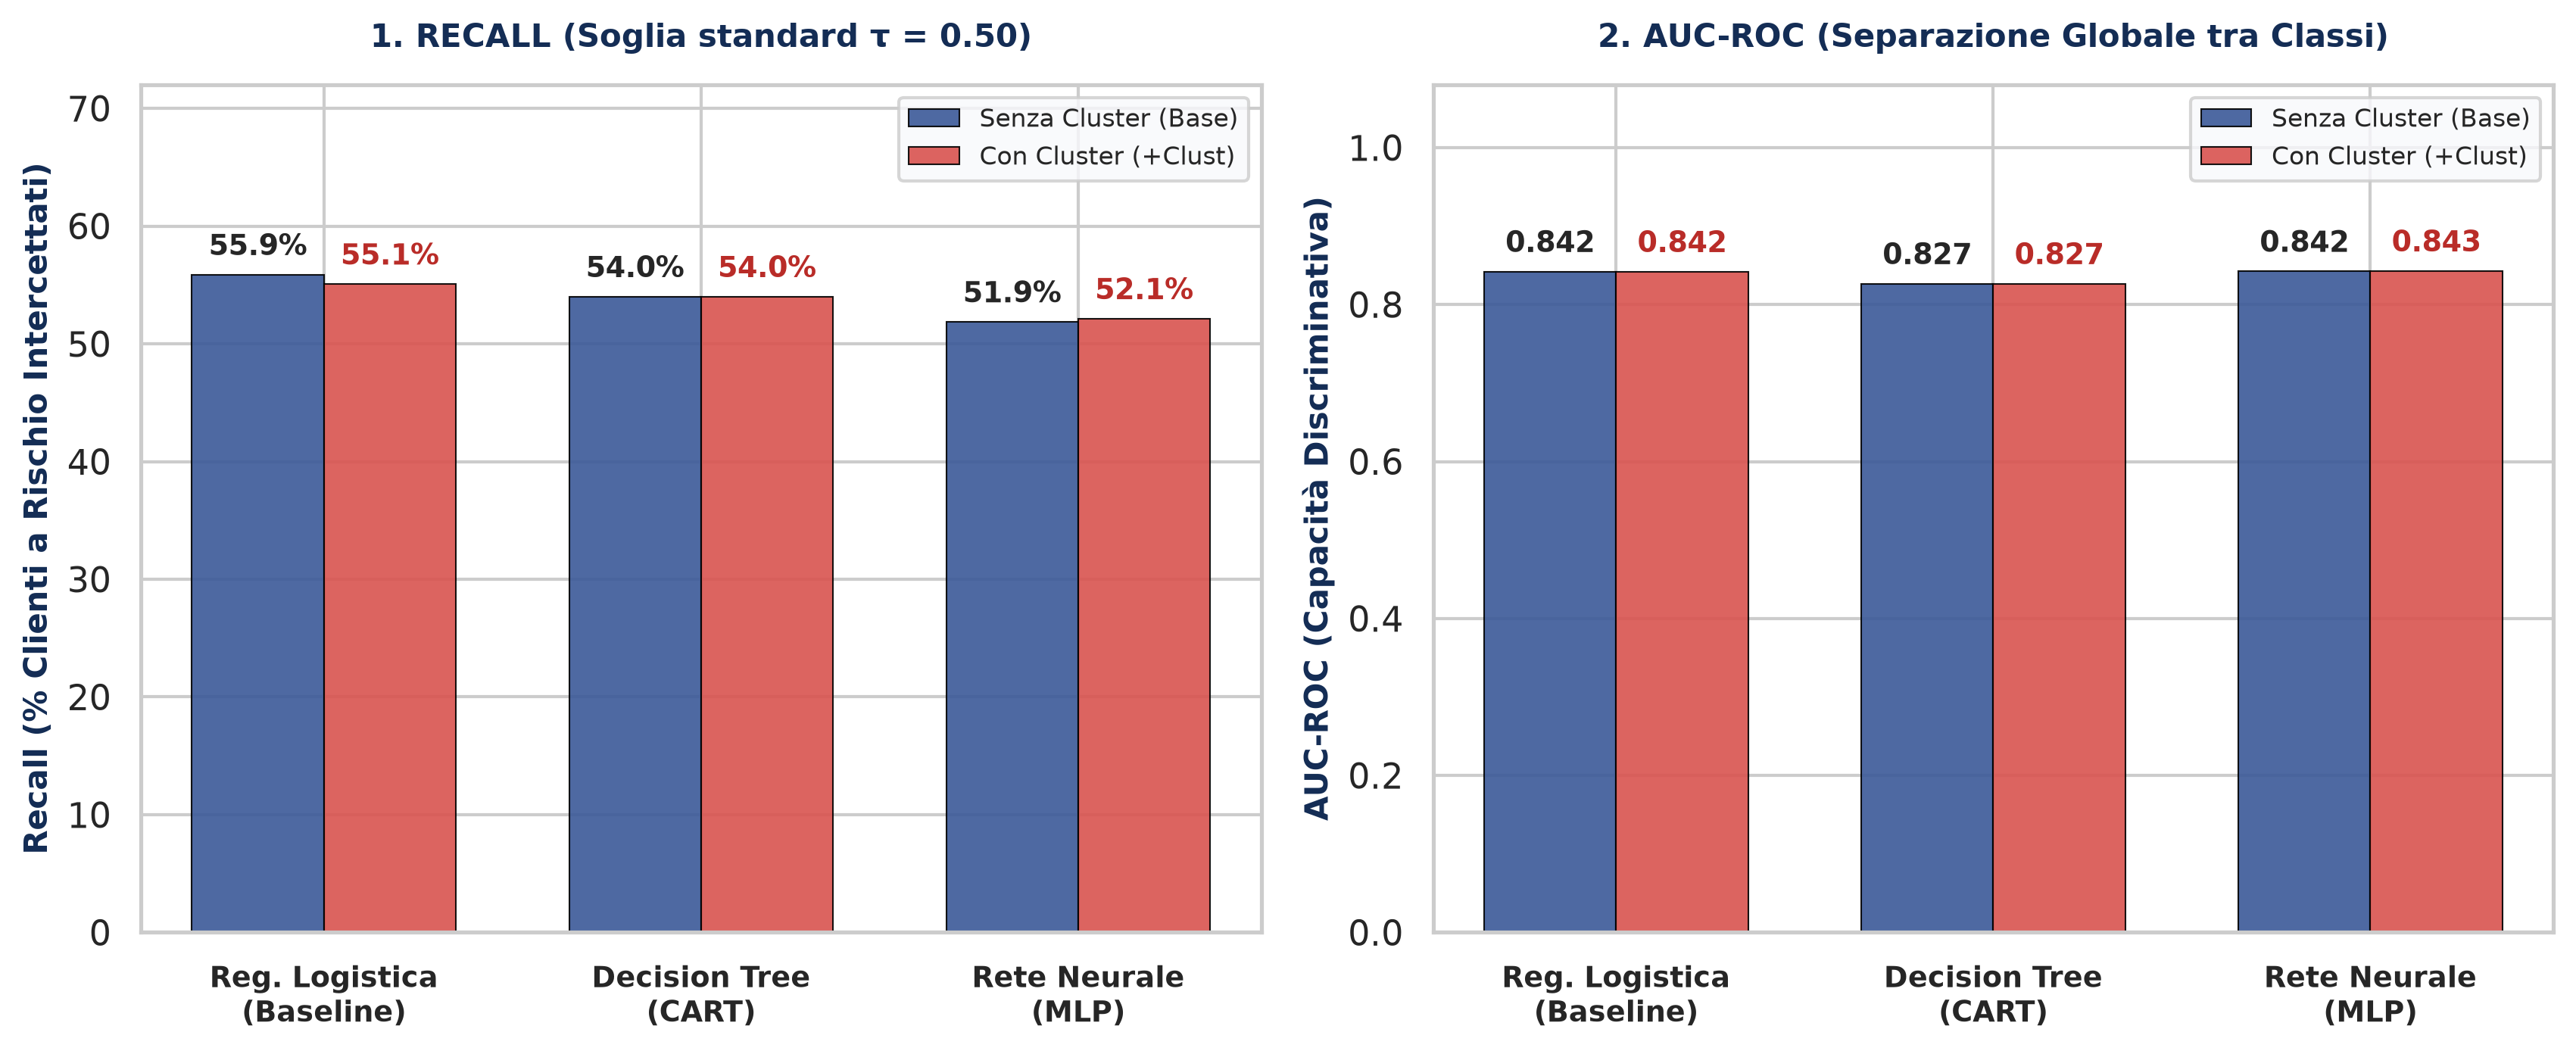

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.8), dpi=300)

labels_short = ['Reg. Logistica\n(Baseline)', 'Decision Tree\n(CART)', 'Rete Neurale\n(MLP)']
x = np.arange(len(labels_short))
width = 0.35

color_base = '#3B5998'
color_clust = '#D9534F'

recall_base = (results_df['Recall (Orig)'] * 100).tolist()
recall_clust = (results_df['Recall (Clust)'] * 100).tolist()
auc_base = results_df['AUC (Orig)'].tolist()
auc_clust = results_df['AUC (Clust)'].tolist()

# --- Subplot 1: RECALL ---
rects1 = ax1.bar(x - width/2, recall_base, width, label='Senza Cluster (Base)', color=color_base, alpha=0.9, edgecolor='black', linewidth=0.5)
rects2 = ax1.bar(x + width/2, recall_clust, width, label='Con Cluster (+Clust)', color=color_clust, alpha=0.9, edgecolor='black', linewidth=0.5)

ax1.set_ylabel('Recall (% Clienti a Rischio Intercettati)', fontsize=10, fontweight='bold', color='#142D55')
ax1.set_title('1. RECALL (Soglia standard τ = 0.50)', fontsize=10, fontweight='bold', color='#142D55', pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(labels_short, fontsize=9, fontweight='bold')
ax1.set_ylim(0, 72)
ax1.legend(frameon=True, facecolor='#F8F9FC', fontsize=8, loc='upper right')

for rect in rects1:
    h = rect.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#B92C28')

# --- Subplot 2: AUC-ROC ---
rects3 = ax2.bar(x - width/2, auc_base, width, label='Senza Cluster (Base)', color=color_base, alpha=0.9, edgecolor='black', linewidth=0.5)
rects4 = ax2.bar(x + width/2, auc_clust, width, label='Con Cluster (+Clust)', color=color_clust, alpha=0.9, edgecolor='black', linewidth=0.5)

ax2.set_ylabel('AUC-ROC (Capacità Discriminativa)', fontsize=10, fontweight='bold', color='#142D55')
ax2.set_title('2. AUC-ROC (Separazione Globale tra Classi)', fontsize=10, fontweight='bold', color='#142D55', pad=12)
ax2.set_xticks(x)
ax2.set_xticklabels(labels_short, fontsize=9, fontweight='bold')
ax2.set_ylim(0, 1.08)
ax2.legend(frameon=True, facecolor='#F8F9FC', fontsize=8, loc='upper right')

for rect in rects3:
    h = rect.get_height()
    ax2.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
for rect in rects4:
    h = rect.get_height()
    ax2.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#B92C28')

plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/confronto_prestazioni_barre.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Analisi dell'Interpretabilità del Decision Tree (White-Box)
Visualizziamo i primi 3 livelli dell'albero CART addestrato sul Training Set non standardizzato (`5.634` istanze): in questo modo le soglie sugli split (`tenure` in mesi, `TotalCharges` in Euro) risultano immediatamente interpretabili dal management aziendale.

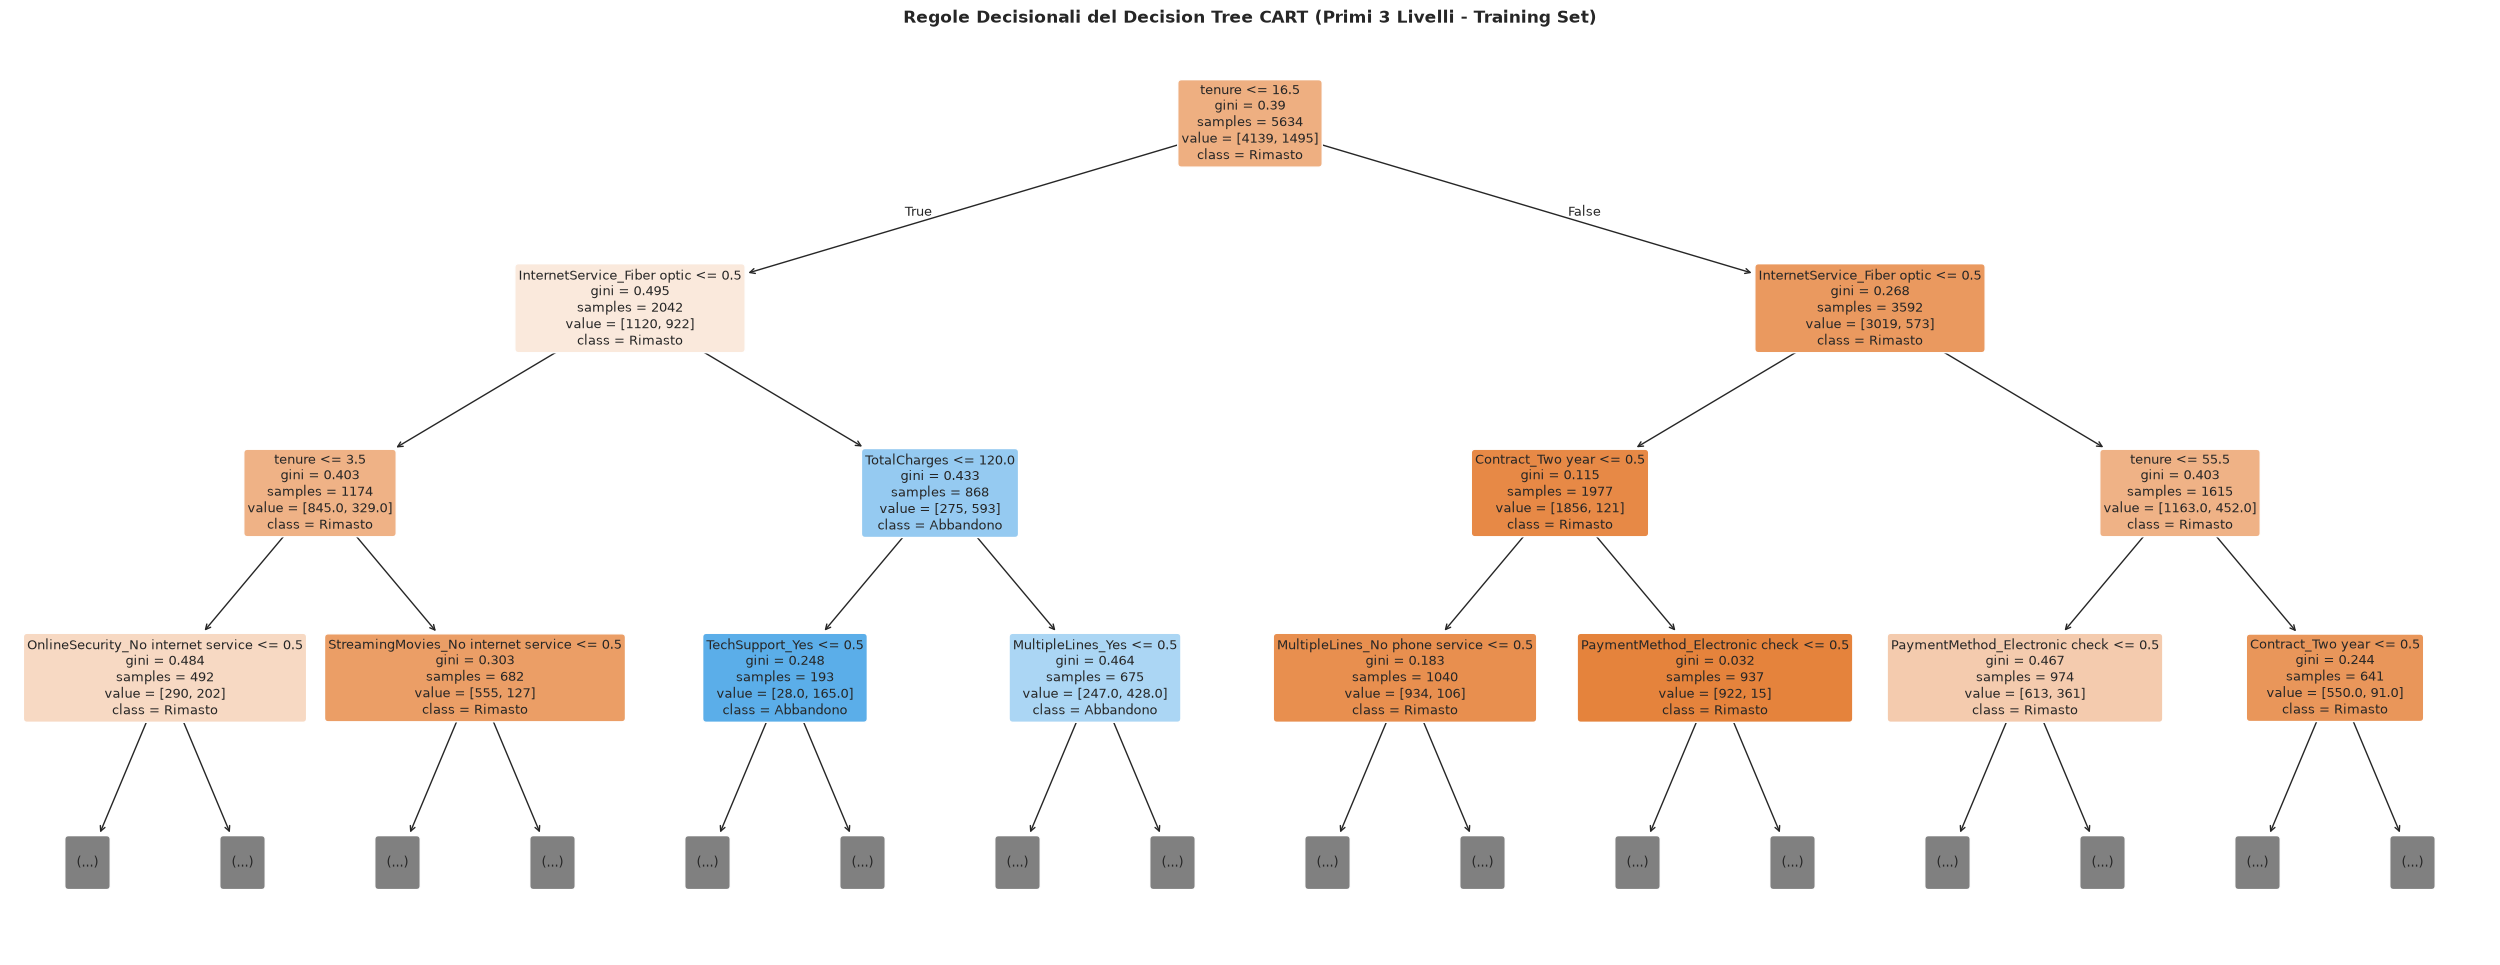

Regole testuali (primi 3 livelli):
|--- tenure <= 16.50
|   |--- InternetService_Fiber optic <= 0.50
|   |   |--- tenure <= 3.50
|   |   |   |--- OnlineSecurity_No internet service <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- OnlineSecurity_No internet service >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- tenure >  3.50
|   |   |   |--- StreamingMovies_No internet service <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- StreamingMovies_No internet service >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- InternetService_Fiber optic >  0.50
|   |   |--- TotalCharges <= 120.00
|   |   |   |--- TechSupport_Yes <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- TechSupport_Yes >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- TotalCharges >  120.00
|   |   |   |--- MultipleLines_Yes <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |---

In [14]:
dt_model_orig = fitted_models['Decision Tree (CART)']['orig']

plt.figure(figsize=(32, 12))
plot_tree(
    dt_model_orig,
    max_depth=3,
    feature_names=X_train_tree_df.columns,
    class_names=['Rimasto', 'Abbandono'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Regole Decisionali del Decision Tree CART (Primi 3 Livelli - Training Set)", fontweight='bold')
plt.savefig(f'{IMAGES_DIR}/albero_decisionale.png', dpi=300, bbox_inches='tight')
plt.show()

print("Regole testuali (primi 3 livelli):")
print(export_text(dt_model_orig, feature_names=list(X_train_tree_df.columns), max_depth=3))

## 9. Discussione dei Risultati e Conclusioni
Dall'analisi sperimentale priva di data leakage emergono tre conclusioni chiave:
1. **Regole White-Box del Decision Tree:**
   - La radice dell'albero isola subito la permanenza breve (`tenure <= 16.5` mesi) come primo fattore di rischio.
   - Il ramo critico verso l'abbandono combina `tenure <= 16.5` mesi e abbonamento in **Fibra Ottica** (`InternetService_Fiber optic > 0.5`), identificando nodi terminali ad altissima concentrazione di churn (in particolare per nuovi clienti con `TotalCharges <= 120.0 €` e assenza di `TechSupport`).
2. **Ruolo Reale del Clustering:**
   - L'aggiunta della feature di cluster One-Hot produce un lieve calo sulla Regressione Logistica (ridondanza/collinearità con `tenure` e spesa già modellate linearmente), lascia invariato il Decision Tree (`Acc = 79.42%`, `Rec = 54.01%`) e apporta un miglioramento moderato sull'MLP regolarizzato (`Acc`: `79.99% -> 80.34%`, `Recall`: `51.87% -> 52.14%`, `F1`: `0.5791 -> 0.5847`, `AUC`: `0.8424 -> 0.8429`, il valore AUC più alto tra tutti i modelli).
   - Il valore principale del clustering K-Means rimane quindi **descrittivo e strategico**: segmenta la base clienti in tre gruppi azionabili (Volatili `43.4%` churn, Fedeli High-Value `15.9%`, Low-Cost `7.2%`) guidando campagne di retention differenziate.
3. **Confronto tra Modelli, Rasoio di Occam e Trade-off CAC:**
   - Con regolarizzazione L2 ed *early stopping* (Lezione 08), l'MLP evita l'overfitting e raggiunge la Regressione Logistica (`AUC ~ 0.842–0.843`), ma per il **Rasoio di Occam** (principio di parsimonia) la **Regressione Logistica** resta preferibile come modello di riferimento per semplicità, convessità, trasparenza dei coefficienti e miglior equilibrio tra Recall (`55.88%`) e F1 (`0.6049`) alla soglia standard.
   - Infine, calibrare la soglia decisionale (es. $\tau = 0.35$) o impostare `class_weight='balanced'` consente di elevare la Recall fino al **78.34%** (`F1 = 0.6136`), allineando l'agente razionale alla minimizzazione delle perdite legate al CAC.